# Lab 4B — LSTM and GRU: learning when to remember and forget
**TEACHER — commented worked solutions** · Beginner MSc · **~2 hours** (plus optional extension)

**Follow-up to Lab 4A (SimpleRNN).** The starting point is exactly the same kind of synthetic process-sensor forecasting task: **50 observed samples → 10 future values**. We now replace `SimpleRNN` by `LSTM` and `GRU` without changing the forecasting task or evaluation protocol.

**Learning outcomes**
1. Explain how LSTM cell state `c[t]` differs from hidden state `h[t]`, and how the gates are applied componentwise.
2. Explain the GRU update/reset gates and its single-state design.
3. Identify Keras tensor shapes and compare trainable parameter counts.
4. Train and fairly compare SimpleRNN, LSTM, GRU, persistence and Ridge regression.
5. Inspect **errors at each forecast horizon**, not only one aggregate number.

**Lab rules:** run cells in order; never use test data for fitting or model selection; answer the conceptual questions. Some code blocks have clearly marked **TODO** lines. All data are synthetic and generated locally; a GPU is not required.

**Lecture connection:** Blocks 4.E–4.J of *Recurrent Neural Networks for Temporal Data* (LSTM, GRU, forecasting and design choices).

## 0. Environment (5 minutes)
As in Lab 4A, we use **Keras 3 with its PyTorch backend**. The cell below must run before any other `import keras`. You can also choose the TensorFlow backend if that is how Keras is configured in your course.

Install locally if needed: `pip install keras torch numpy matplotlib scikit-learn`.

`KERAS_BACKEND` must be selected **before** importing Keras. A new notebook kernel is required if you change the backend.

In [1]:
# Setup and reproducibility — no GPU required.
import os
os.environ["KERAS_BACKEND"] = "torch"
os.environ.setdefault("OMP_NUM_THREADS", "2")

import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
import keras

SEED = 17
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)

print("Keras version:", keras.__version__)
print("Active backend:", keras.backend.backend())
print("NumPy version:", np.__version__)

Keras version: 3.13.2
Active backend: torch
NumPy version: 2.3.5


## 1. LSTM — a numerical memory-update exercise (15 minutes)
The LSTM maintains **two recurrent state vectors**, each containing one component per unit:

- `c[t]`: cell state, updated through a gated **additive memory pathway**.
- `h[t]`: hidden state, used by the output layer and the next recurrent update.

Given forget `f[t]`, input `i[t]`, candidate `g[t]`, and output `o[t]` vectors:

`c[t] = f[t] * c[t-1] + i[t] * g[t]`  
`h[t] = o[t] * tanh(c[t])`

The multiplications `*` are **elementwise**, not matrix multiplication. Below the gate values are **supplied for illustration**; in a trained LSTM they are recomputed from the current input and previous hidden state using learned weights.

In [2]:
# Illustrative two-unit LSTM cell. Each array has shape [2].
c_previous = np.array([1.00, -0.50])
forget = np.array([0.95, 0.20])
input_gate = np.array([0.10, 0.80])
candidate = np.array([0.40, -0.30])
output_gate = np.array([0.10, 0.90])

print("Previous cell state: ", c_previous)
print("Forget gate:         ", forget)
print("Input gate:          ", input_gate)
print("Candidate memory:    ", candidate)
print("Output gate:         ", output_gate)

Previous cell state:  [ 1.  -0.5]
Forget gate:          [0.95 0.2 ]
Input gate:           [0.1 0.8]
Candidate memory:     [ 0.4 -0.3]
Output gate:          [0.1 0.9]


In [3]:
# The old cell memory is selectively retained and new candidate content is added.
retained_old = forget * c_previous      # contribution of old memory
written_new = input_gate * candidate    # contribution of new candidate
c_new = retained_old + written_new

# The output gate controls how much of tanh(c_new) becomes visible as h_new.
h_new = output_gate * np.tanh(c_new)
print("Retained old memory:", retained_old)
print("Written new memory: ", written_new)
print("New cell state:    ", c_new)
print("New hidden state:  ", h_new)
assert np.allclose(c_new, [0.99, -0.34])

Retained old memory: [ 0.95 -0.1 ]
Written new memory:  [ 0.04 -0.24]
New cell state:     [ 0.99 -0.34]
New hidden state:   [ 0.07573623 -0.29472966]


**Question.** Can the LSTM keep a large value in `c[t]` while exposing only a small value in `h[t]`? What changes if we change only the output gate?

**Instructor discussion.** Yes. `c[t]` is updated using the forget/input gates, while `h[t] = o[t] * tanh(c[t])`. Changing only `o[t]` changes the current hidden state but does **not** modify the already computed `c[t]`. In the example, the first memory component is `0.99` while its hidden-state component is only about `0.076`, because its output gate is `0.10`.

### Visual check: changing only the output gate
This is an illustrative numerical experiment, **not a plot of gates learned by the trained network**.

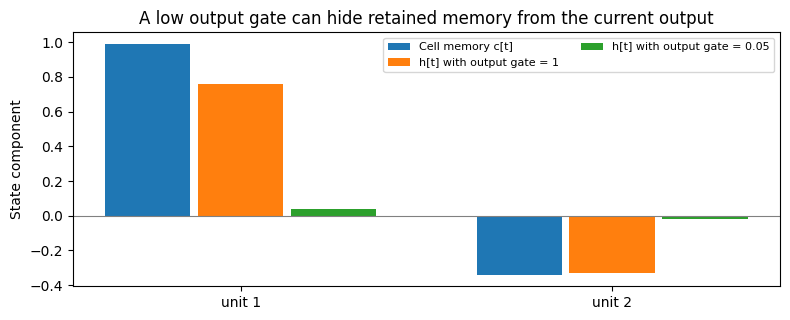

In [4]:
# Both examples share EXACTLY the same stored cell memory.
h_open = np.ones_like(c_new) * np.tanh(c_new)
h_closed = np.full_like(c_new, 0.05) * np.tanh(c_new)
x_positions = np.arange(len(c_new))
plt.figure(figsize=(8, 3.3))
plt.bar(x_positions - 0.25, c_new, width=0.23, label="Cell memory c[t]")
plt.bar(x_positions, h_open, width=0.23, label="h[t] with output gate = 1")
plt.bar(x_positions + 0.25, h_closed, width=0.23, label="h[t] with output gate = 0.05")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xticks(x_positions, ["unit 1", "unit 2"])
plt.ylabel("State component")
plt.title("A low output gate can hide retained memory from the current output")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 2. GRU — one state, two gates (10 minutes)
A GRU has a single recurrent state `h[t]`. Conceptually:

- The **reset gate** controls how much previous-state information enters the *candidate computation*.
- The **update gate** controls the mixture of the old hidden state and candidate state.

We use the following **explicit convention** in this toy example:

`h[t] = z[t] * h[t-1] + (1-z[t]) * h_candidate[t]`

Thus, **z near 1 favors retaining old state**. Some descriptions use the complementary convention, so always check the chosen formula. The toy gate values below are already given.

In [5]:
h_previous = np.array([0.70, -0.50])
z_keep_old = np.array([0.90, 0.20])
h_candidate = np.array([-0.20, 0.80])
print("Previous hidden state:", h_previous)
print("Update gate:         ", z_keep_old)
print("Candidate state:     ", h_candidate)

Previous hidden state: [ 0.7 -0.5]
Update gate:          [0.9 0.2]
Candidate state:      [-0.2  0.8]


In [6]:
# Keep a fraction z of the old state, replace the rest with the candidate.
h_gru = z_keep_old * h_previous + (1.0 - z_keep_old) * h_candidate
print("New GRU hidden state:", h_gru)
assert np.allclose(h_gru, [0.61, 0.54])

New GRU hidden state: [0.61 0.54]


**Question.** What role does the GRU reset gate play? Does it directly multiply the old state in the final mixture above?

**Instructor discussion.** The reset gate affects how much of the previous hidden state is used while **constructing the candidate state**. It does not appear explicitly in the final mixture when the already computed candidate is provided. The exact candidate computation depends on the GRU implementation; Keras uses `reset_after=True` by default.

## 3. Why gated memory may help (5–10 minutes)
To build intuition, imagine that an LSTM memory component receives **no new content** (`i[t] * g[t] = 0`). Then `c[t] = f * c[t-1]`. If `f` is near 1, the stored value decays slowly. This does not mean the network automatically learns the appropriate `f`: it must learn it from data.

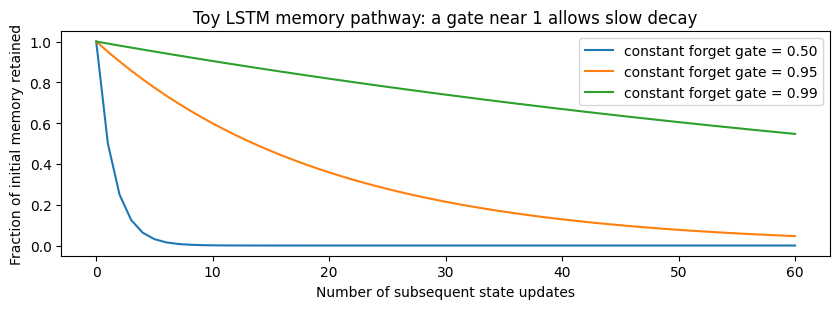

In [7]:
steps = np.arange(0, 61)
plt.figure(figsize=(8.5, 3.2))
for constant_forget in [0.50, 0.95, 0.99]:
    trace = constant_forget ** steps   # illustrative c[0] = 1, no new writes
    plt.plot(steps, trace, label=f"constant forget gate = {constant_forget:.2f}")
plt.xlabel("Number of subsequent state updates")
plt.ylabel("Fraction of initial memory retained")
plt.title("Toy LSTM memory pathway: a gate near 1 allows slow decay")
plt.legend()
plt.tight_layout()
plt.show()

**Question.** Why does this memory mechanism help with long dependencies, but not guarantee successful learning?

**Instructor discussion.** The additive cell-state update offers a path for information and gradients to persist when the forget gate is near 1. However, gate values are learned, and optimization, data quality, capacity and sequence length all matter. LSTM/GRU models can still forget useful information or overfit.

## 4. Forecasting dataset — the same setting as Lab 4A (10 minutes)
We generate **independent sensor recordings** consisting of oscillations, drift and noise. The input history is 50 samples and the direct forecast is the next 10 samples.

To avoid leakage, **split recordings into train / validation / test first**, then construct overlapping windows independently within each split. No observation from a test recording appears in a training window.

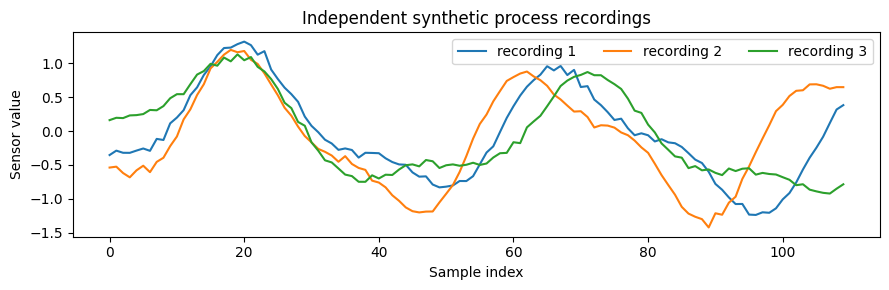

In [8]:
# Same generator and configuration as Lab 4A so the comparison has context.
RECORD_LENGTH = 180
N_TRAIN, N_VAL, N_TEST = 16, 4, 4
L, H, STRIDE = 50, 10, 3

def generate_recording(generator, length=RECORD_LENGTH):
    """Create one independent, mildly nonstationary process recording."""
    t = np.arange(length, dtype=np.float32)
    phase = generator.uniform(0, 2 * np.pi)
    amplitude = generator.uniform(0.75, 1.25)
    speed = generator.uniform(0.105, 0.145)
    slow = amplitude * np.sin(speed * t + phase)
    faster = 0.30 * np.sin(2.2 * speed * t + 0.45 * phase)
    drift = 0.20 * np.cos(0.035 * t + generator.uniform(-1, 1))
    noise = generator.normal(0, 0.035, size=length)
    return (slow + faster + drift + noise).astype("float32")

recordings = [generate_recording(rng) for _ in range(N_TRAIN + N_VAL + N_TEST)]
train_records = recordings[:N_TRAIN]
val_records = recordings[N_TRAIN:N_TRAIN + N_VAL]
test_records = recordings[N_TRAIN + N_VAL:]

plt.figure(figsize=(9, 3))
for j in range(3):
    plt.plot(recordings[j][:110], label=f"recording {j + 1}")
plt.xlabel("Sample index")
plt.ylabel("Sensor value")
plt.title("Independent synthetic process recordings")
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

In [9]:
def make_windows(recording_list, history=L, horizon=H, stride=STRIDE):
    """Create supervised samples from whole recordings, without cross-split mixing.

    X: [N, history, 1]     (the observed past)
    Y: [N, horizon]        (the future after the last observed sample)
    """
    features, targets = [], []
    for recording in recording_list:
        last_start = len(recording) - history - horizon
        for start in range(0, last_start + 1, stride):
            past = recording[start:start + history]
            future = recording[start + history:start + history + horizon]
            features.append(past[:, None])   # d = 1 input variable
            targets.append(future)
    return (np.asarray(features, dtype="float32"),
            np.asarray(targets, dtype="float32"))

X_train, Y_train = make_windows(train_records)
X_val, Y_val = make_windows(val_records)
X_test, Y_test = make_windows(test_records)

print("Train:", X_train.shape, Y_train.shape)
print("Valid:", X_val.shape, Y_val.shape)
print("Test: ", X_test.shape, Y_test.shape)

assert X_train.ndim == 3 and X_train.shape[1:] == (L, 1)
assert Y_train.shape == (len(X_train), H)
assert len(X_val) > 0 and len(X_test) > 0

Train: (656, 50, 1) (656, 10)
Valid: (164, 50, 1) (164, 10)
Test:  (164, 50, 1) (164, 10)


**Question.** Why is each input shape `[N, 50, 1]`, while each target shape is `[N, 10]`?

**Instructor discussion.** `N` is the number of windows, `50` is the time dimension, and `1` is the number of sensor variables per time step. We request ten future values from the entire window, so the target has ten output coordinates and **no input-time axis**. This is direct multi-horizon, sequence-to-vector forecasting.

## 5. Inspect Keras LSTM and GRU states and parameter counts (15 minutes)
For `d` input features per step and `U` recurrent units:

- SimpleRNN: `U * (d + U + 1)` recurrent-layer parameters.
- LSTM: `4 * U * (d + U + 1)` recurrent-layer parameters (four sets of transformations).
- GRU **with Keras default `reset_after=True`**: `3 * U * (d + U + 2)` recurrent-layer parameters. The extra term reflects Keras's two bias vectors.

The final `Dense(H)` layer adds `(U + 1) * H` parameters to **each** forecaster. The number of learned parameters does **not** depend on the number of input time steps.

In [10]:
UNITS = 16          # same state dimension for all architectures
D = X_train.shape[2]  # input channels (1 in this lab)
print("Expected recurrent-layer parameters (without the Dense output layer):")
print("SimpleRNN:", UNITS * (D + UNITS + 1))
print("LSTM:     ", 4 * UNITS * (D + UNITS + 1))
print("GRU:      ", 3 * UNITS * (D + UNITS + 2))

# return_state=True exposes Keras' stored states for inspection.
lstm_layer = keras.layers.LSTM(UNITS, return_state=True)
final_out_lstm, last_h_lstm, last_c_lstm = lstm_layer(X_train[:3])
gru_layer = keras.layers.GRU(UNITS, return_state=True)
final_out_gru, last_h_gru = gru_layer(X_train[:3])

print("LSTM: final output, h, c =", final_out_lstm.shape,
      last_h_lstm.shape, last_c_lstm.shape)
print("GRU:  final output, h    =", final_out_gru.shape,
      last_h_gru.shape)
print("Actual LSTM recurrent-layer params:", lstm_layer.count_params())
print("Actual GRU recurrent-layer params: ", gru_layer.count_params())
assert lstm_layer.count_params() == 4 * UNITS * (D + UNITS + 1)
assert gru_layer.count_params() == 3 * UNITS * (D + UNITS + 2)

Expected recurrent-layer parameters (without the Dense output layer):
SimpleRNN: 288
LSTM:      1152
GRU:       912
LSTM: final output, h, c = torch.Size([3, 16]) torch.Size([3, 16]) torch.Size([3, 16])
GRU:  final output, h    = torch.Size([3, 16]) torch.Size([3, 16])
Actual LSTM recurrent-layer params: 1152
Actual GRU recurrent-layer params:  912


**Question.** Does `h[t]` in LSTM mean the observed physical output of the sensor? Why are LSTM `h[t]` and `c[t]` both length 16?

**Instructor discussion.** `h[t]` is an internal learned representation **made available to subsequent layers**, not the physical sensor output. The sensor forecast is produced by a separate `Dense` layer. An LSTM with 16 units maintains **two** 16-dimensional recurrent states; this differs from a GRU, which has one 16-dimensional state.

## 6. Build fair sequence-to-vector models (15 minutes)
All three models will use exactly the same history, output head, number of recurrent units, loss, optimizer, training budget and stopping rule. They differ only in the recurrent **cell type**.

**Note:** equal unit counts do *not* mean equal parameter counts. That difference is part of the engineering trade-off.

In [11]:
# The code below differs only in the recurrent cell class.
CELL_TYPES = {
    "SimpleRNN": keras.layers.SimpleRNN,
    "LSTM": keras.layers.LSTM,
    "GRU": keras.layers.GRU,
}

def build_forecaster(cell_name, units=UNITS, horizon=H):
    """Build [N,50,1] -> recurrent state [N,units] -> [N,10] forecasts.

    Using Dense(horizon) means all horizons are predicted DIRECTLY.
    We do not feed previous predicted values back into the input.
    """
    cell_class = CELL_TYPES[cell_name]
    model = keras.Sequential([
        keras.Input(shape=(L, D)),       # [N, 50, 1]
        cell_class(units),               # [N, units], last hidden state
        keras.layers.Dense(horizon),    # [N, 10] target values
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.003, global_clipnorm=1.0),
        loss="mse",
    )
    return model

example_model = build_forecaster("LSTM")
print("One model output shape:", example_model(X_train[:5]).shape)
example_model.summary()
assert tuple(example_model(X_train[:5]).shape) == (5, H)

One model output shape: torch.Size([5, 10])


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,322 (5.16 KB)

 Trainable params: 1,322 (5.16 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compare TOTAL parameters, including the common Dense(10) head.
for name in ["SimpleRNN", "LSTM", "GRU"]:
    model = build_forecaster(name)
    print(f"{name:10s} {model.count_params():5d} total trainable parameters")

SimpleRNN    458 total trainable parameters
LSTM        1322 total trainable parameters
GRU         1082 total trainable parameters


## 7. Baselines and model training (25–30 minutes)
Before training the gated models, establish simple reference forecasts. A complicated model is not automatically better.

- **Persistence:** repeat the most recent observation at every forecast horizon.
- **Ridge:** fit a direct 10-output regression using the 50 lagged samples as tabular columns.

We evaluate *test* results only after the training configurations are fixed. In practice, hyperparameters must be chosen using training/validation only.

In [13]:
def mse(y_true, y_pred):
    """MSE with an explicit shape check to prevent NumPy broadcasting bugs."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert y_true.shape == y_pred.shape, (y_true.shape, y_pred.shape)
    return float(np.mean((y_true - y_pred) ** 2))

# Persistence: take the last observed sensor value and repeat it H times.
pred_persistence = np.repeat(X_test[:, -1, 0:1], repeats=H, axis=1)

# Ridge expects tabular inputs [N, p] rather than [N, L, d].
ridge = Ridge(alpha=1.0)
ridge.fit(X_train[:, :, 0], Y_train)  # use TRAIN ONLY for fitting
pred_ridge = ridge.predict(X_test[:, :, 0])

print("Persistence test MSE:", round(mse(Y_test, pred_persistence), 5))
print("Ridge test MSE:      ", round(mse(Y_test, pred_ridge), 5))

Persistence test MSE: 0.35341
Ridge test MSE:       0.0282


In [14]:
# Exactly the same fitting protocol for all recurrent cell types.
ARCHITECTURES = ["SimpleRNN", "LSTM", "GRU"]
models, histories, predictions, training_seconds = {}, {}, {}, {}

for name in ARCHITECTURES:
    keras.utils.set_random_seed(SEED)
    model = build_forecaster(name)
    # Stop using VALIDATION error, not test error.
    stopping_rule = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.perf_counter()
    history = model.fit(
        X_train, Y_train,
        validation_data=(X_val, Y_val),
        epochs=12, batch_size=64,
        callbacks=[stopping_rule],
        verbose=0,
    )
    training_seconds[name] = time.perf_counter() - t0
    models[name] = model
    histories[name] = history
    predictions[name] = model.predict(X_test, verbose=0)
    # Verify the same [N,H] shape before any error metric.
    assert predictions[name].shape == Y_test.shape
    print(f"{name:10s}: params={model.count_params():4d}, "
          f"epochs={len(history.history['loss']):2d}, "
          f"MSE={mse(Y_test, predictions[name]):.5f}")

SimpleRNN : params= 458, epochs=12, MSE=0.08597


LSTM      : params=1322, epochs=12, MSE=0.11575


GRU       : params=1082, epochs=12, MSE=0.07051


## 8. Interpret forecast errors by horizon (15 minutes)
A single MSE combines all ten horizons and can hide errors at the most operationally important horizons. Examine the **per-horizon MAE** and example forecast shapes.

Note: training time is implementation- and hardware-dependent; it is not an intrinsic property of the architecture.

In [15]:
# A compact and fair comparison table: identical test recording set for all rows.
all_predictions = {"Persistence": pred_persistence, "Ridge": pred_ridge}
all_predictions.update(predictions)

print(f"{'Method':14s} {'Test MSE':>10s} {'Test MAE':>10s} {'Parameters':>12s} {'Training(s)':>12s}")
print("-" * 64)
for name, pred in all_predictions.items():
    parameter_count = models[name].count_params() if name in models else "-"
    train_time = f"{training_seconds[name]:.2f}" if name in training_seconds else "-"
    mae = np.mean(np.abs(Y_test - pred))
    print(f"{name:14s} {mse(Y_test, pred):10.5f} {mae:10.5f} "
          f"{str(parameter_count):>12s} {train_time:>12s}")

Method           Test MSE   Test MAE   Parameters  Training(s)
----------------------------------------------------------------
Persistence       0.35341    0.45509            -            -
Ridge             0.02820    0.12019            -            -
SimpleRNN         0.08597    0.22492          458         3.99
LSTM              0.11575    0.26837         1322         6.91
GRU               0.07051    0.19702         1082         6.80


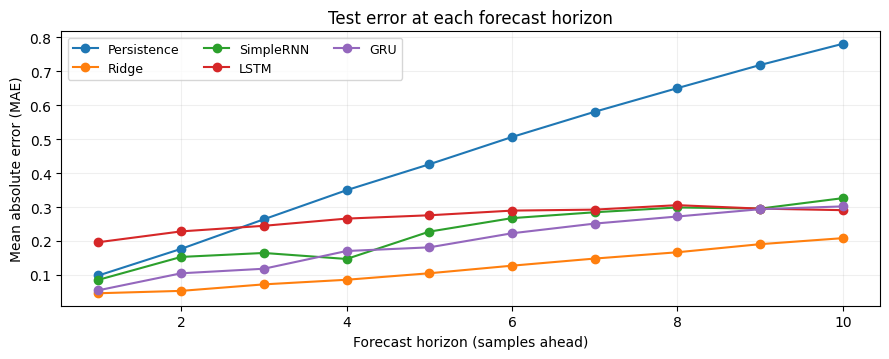

In [16]:
# Average the absolute errors over test WINDOWS (axis=0), not horizons.
plt.figure(figsize=(9, 3.7))
horizons = np.arange(1, H + 1)
for name, pred in all_predictions.items():
    mae_by_horizon = np.mean(np.abs(Y_test - pred), axis=0)
    assert mae_by_horizon.shape == (H,)
    plt.plot(horizons, mae_by_horizon, marker="o", label=name)
plt.xlabel("Forecast horizon (samples ahead)")
plt.ylabel("Mean absolute error (MAE)")
plt.title("Test error at each forecast horizon")
plt.legend(ncol=3, fontsize=9)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

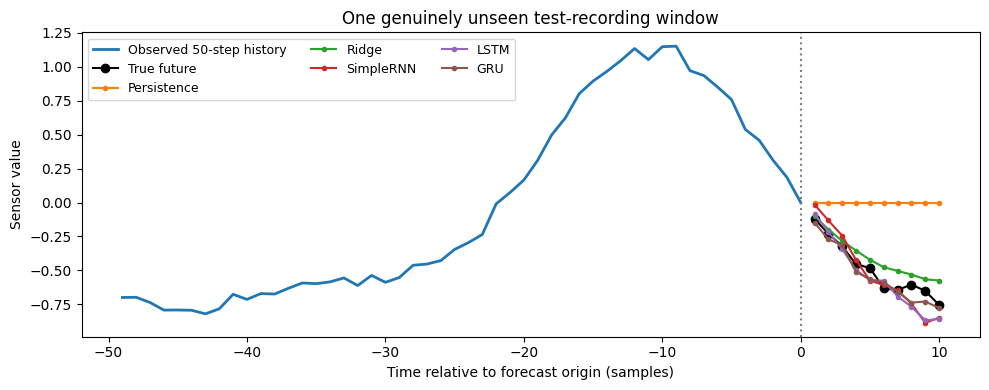

In [17]:
# Example: observed history is at relative times -49,...,0; future is 1,...,10.
example = 6
plt.figure(figsize=(10, 4))
plt.plot(np.arange(-L + 1, 1), X_test[example, :, 0],
         label="Observed 50-step history", linewidth=2)
plt.plot(np.arange(1, H + 1), Y_test[example], "ko-", label="True future")
for name in ["Persistence", "Ridge", "SimpleRNN", "LSTM", "GRU"]:
    plt.plot(np.arange(1, H + 1), all_predictions[name][example],
             marker=".", label=name)
plt.axvline(0, color="gray", linestyle=":")
plt.xlabel("Time relative to forecast origin (samples)")
plt.ylabel("Sensor value")
plt.title("One genuinely unseen test-recording window")
plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

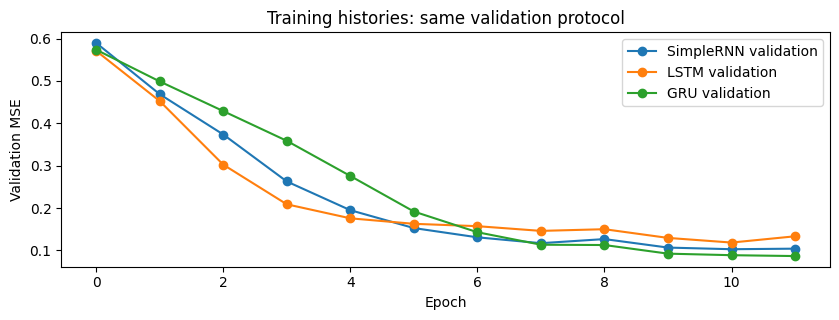

In [18]:
# This graph reveals potential overfitting and differences in optimization.
plt.figure(figsize=(8.5, 3.3))
for name, history in histories.items():
    plt.plot(history.history["val_loss"], marker="o", label=f"{name} validation")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Training histories: same validation protocol")
plt.legend()
plt.tight_layout()
plt.show()

**Question.** Which method would you recommend based on the test table and per-horizon error curves? Is the model with the largest parameter count necessarily preferable?

**Instructor discussion.** There is no universally correct model. Choose using the **validation** protocol, and then report the held-out test results. Assess per-horizon errors together with parameter count, training/inference cost and robustness. In these synthetic data, linear Ridge may remain highly competitive, and neither LSTM nor GRU is guaranteed to win simply because of gating. Avoid selecting models by repeatedly inspecting test performance.

## 9. One final check: sequence-to-vector versus sequence-to-sequence (5 minutes)
In this lab the forecasting head produces a single vector `[N, 10]` from the **final** hidden representation. If we set `return_sequences=True`, the recurrent layer instead returns `[N, 50, 16]`, and applying `Dense(10)` then gives `[N, 50, 10]` — a forecast vector at **every input step**. That is a different training target and not automatically a better forecast.

In [19]:
# No training needed: inspect the output shapes only.
seq_to_vector = keras.Sequential([
    keras.Input(shape=(L, D)),
    keras.layers.GRU(UNITS),
    keras.layers.Dense(H),
])
seq_to_seq = keras.Sequential([
    keras.Input(shape=(L, D)),
    keras.layers.GRU(UNITS, return_sequences=True),
    keras.layers.Dense(H),  # Keras Dense maps the LAST axis at every step.
])
print("Sequence-to-vector output:", seq_to_vector(X_test[:4]).shape)
print("Sequence-to-sequence output:", seq_to_seq(X_test[:4]).shape)
# Dense(H) already works on a 3-D tensor: TimeDistributed(Dense(H)) is optional.
assert tuple(seq_to_vector(X_test[:4]).shape) == (4, H)
assert tuple(seq_to_seq(X_test[:4]).shape) == (4, L, H)

Sequence-to-vector output: torch.Size([4, 10])
Sequence-to-sequence output: torch.Size([4, 50, 10])


## 10. Exit ticket — report in five sentences
Write a short engineering recommendation addressing:
1. What is different between LSTM `c[t]` and `h[t]`?
2. What is different between LSTM and GRU memory representations?
3. Which of the five forecasting methods is best under your selected evaluation criteria?
4. At which horizon does the chosen method perform poorly, if any?
5. What extra evidence (e.g., additional recordings, changing regimes, latency measurements) would you collect before deployment?

**Instructor note.** Expected answers should avoid the claims “LSTM is always more accurate,” “GRU always trains faster,” or “gated networks remember everything.” They should mention that gates are **time-dependent activations** computed from learned weights, that the test set is held out, and that the synthetic setting is not evidence of deployment robustness.

### Optional extension (15–20 minutes, if time permits)
Repeat with a **longer history** (`L=80`, keeping the same recording-level splits) or a **larger hidden dimension** (`UNITS=32`). Recreate windows and models, then ask: does the improvement justify extra parameters and computation? Change **one design choice at a time**, and make decisions based on validation results.

**Additional discussion:** the toy gate-value calculations above use provided gate values. Keras `LSTM` and `GRU` do not ordinarily expose their internal gate activations as public outputs. Inspecting *actual* learned gate activations requires a customized model/cell or careful extraction of learned weights, and should not be confused with the toy example.